---

# Tugas Besar 2 IF3170 Inteligensi Artifisial
## K-Nearest Neighbors (KNN)

---

## Group 04 TreeIsAllYouNeed

- Gabriella Botimada Lubis (13524006)
- Agatha Tatianingseto (13524008)
- Muhammad Nur Majid (13524028)
- Athilla Zaidan (13524068)
- Reva Natania Sitohang (13524098)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)

---

# Introduction <a name="1"></a>

---

## Overview

Dataset berisi reservasi hotel. Target `is_canceled` menunjukkan apakah sebuah reservasi dibatalkan (`1`) atau tidak (`0`). Pada notebook ini, algoritma KNN dibuat dari scratch dan digunakan untuk mengklasifikasikan reservasi yang belum memiliki label.

## Aim

Mengimplementasikan KNN from scratch, menyiapkan data dengan benar, memilih fitur dan hyperparameter melalui cross-validation, membandingkan hasil dengan scikit-learn, menyimpan dan memuat model, serta menghasilkan submission Kaggle yang reproducible.

## Metric

**Macro F1-score** dipakai untuk memilih konfigurasi karena memperhitungkan kedua kelas secara setara pada data yang tidak seimbang. Accuracy, confusion matrix, precision, dan recall digunakan sebagai informasi pendukung.

## Dataset

- `train.csv`: data berlabel untuk pemodelan.
- `test.csv`: data tanpa label untuk submission Kaggle.
- `sample_submission.csv`: acuan format serta urutan `id`.

Terdapat 17 fitur asli (14 numerik dan 3 kategorikal), satu kolom `id`, dan target `is_canceled` pada training.

## Approach

Data diperiksa dan dibersihkan, lalu fitur kategorikal di-*one-hot encode* dan fitur numerik dinormalisasi dengan Min-Max. Beberapa fitur turunan dibandingkan dengan representasi aslinya. **Feature selection** dilakukan menggunakan 3-fold CV dan baseline tetap Euclidean k=5, setelah itu **dua kandidat fitur** masuk ke tuning 5-fold untuk memilih k dan distance metric. Preprocessing pada setiap CV di-*fit* menggunakan training fold. Konfigurasi terbaik dievaluasi pada holdout 20%, lalu dilatih ulang menggunakan seluruh training bersih sebelum membuat submission. Pemilihan kelas memakai **majority voting**.

---

# Initialization <a name="2"></a>

---

## Environment Setup

Cell berikut mencantumkan library dasar yang digunakan. Perintah instalasi secara default dinonaktifkan dengan menjadikannya komentar.

In [2]:
# %pip install numpy pandas scipy scikit-learn matplotlib

## Import Libraries

Seluruh import diletakkan di cell ini. `KNN` yang dipakai berasal dari implementasi from scratch kelompok, scikit-learn hanya digunakan untuk pembagian data, evaluasi, cross-validation, dan pembanding.

In [3]:
import os
import pickle
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split

search_roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
ROOT = next((path for path in search_roots if (path / "src" / "kaggle" / "dataset" / "train.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Dataset not found in src/kaggle/dataset")
sys.path.insert(0, str(ROOT / "src"))

from kaggle.knn_submission import (
    ALL_FEATURES, CATEGORICAL, ORIGINAL, OUTPUT_DIR, SEED, TARGET,
    BookingPreprocessor, add_features, candidate_features,
    clean_training_data, load_data, restore_preprocessor, run_pipeline
)

## Settings

Path dan konstanta bersama disimpan di kelas ini.

In [4]:
class Settings:
    SEED = 42
    DATA_DIR = ROOT / "src" / "kaggle" / "dataset"
    OUTPUT_DIR = ROOT / "output" / "knn"
    HOLDOUT = 0.2

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
assert CFG.SEED == SEED
assert CFG.OUTPUT_DIR == OUTPUT_DIR

## Seed Everything

Random seed dibuat tetap agar pembagian data dan pengacakan cross-validation dapat direproduksi.

In [5]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

Kolom `id` dipertahankan sebagai string karena merupakan identifier, bukan bilangan yang dapat dipakai untuk menghitung jarak.

In [6]:
train_df, test_df, sample_submission = load_data()
print(f"Training rows = {len(train_df)}")
print(f"Test rows = {len(test_df)}")
display(train_df.head())

Training rows = 27373
Test rows = 6844


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


---

# Data Understanding (Optional) <a name="3"></a>

---

## Describe Data

In [7]:
feature_summary = pd.DataFrame({
    "type": ["categorical" if name in CATEGORICAL else "numeric" for name in ORIGINAL],
    "dtype": train_df[ORIGINAL].dtypes.astype(str).tolist(),
    "missing": train_df[ORIGINAL].isna().sum().to_numpy(),
    "unique_values": train_df[ORIGINAL].nunique().to_numpy()
}, index=ORIGINAL)
display(feature_summary)

,type,dtype,missing,unique_values
num_adults,numeric,float64,809,5
num_children,numeric,float64,3035,6
weekend_nights,numeric,int64,0,8
weekday_nights,numeric,int64,0,18
meal_package,categorical,object,1760,4
needs_parking,numeric,float64,1082,2
room_category,categorical,object,1002,7
days_before_arrival,numeric,float64,1123,407
arrival_year,numeric,int64,0,2
arrival_month,numeric,int64,0,12


## Explore Data

,count,share
is_canceled,,
0,18404,0.672341
1,8969,0.327659


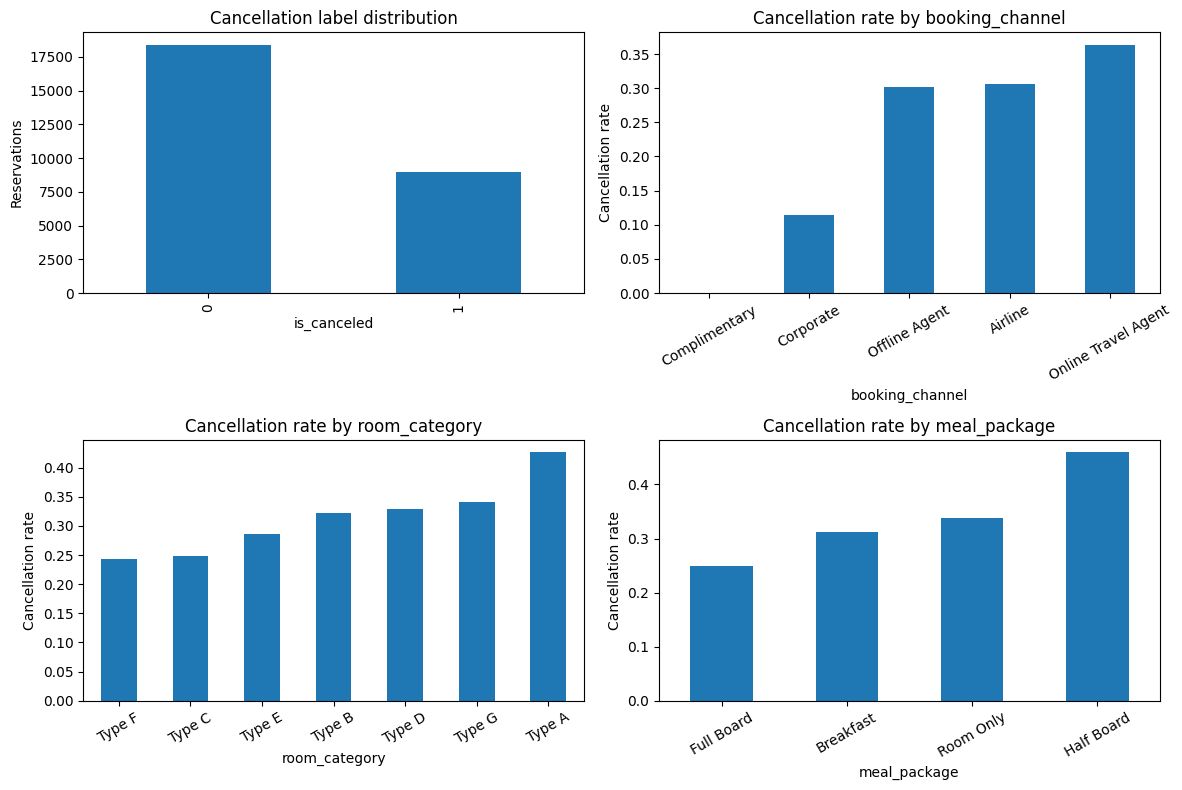

In [8]:
target_share = train_df[TARGET].value_counts(normalize=True).sort_index()

display(pd.DataFrame({
    "count": train_df[TARGET].value_counts().sort_index(),
    "share": target_share
}))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

train_df[TARGET].value_counts().sort_index().plot.bar(ax=axes[0, 0])
axes[0, 0].set_title("Cancellation label distribution")
axes[0, 0].set_xlabel("is_canceled")
axes[0, 0].set_ylabel("Reservations")

for ax, feature in zip(
    [axes[0, 1], axes[1, 0], axes[1, 1]],
    ["booking_channel", "room_category", "meal_package"]
):
    train_df.groupby(feature)[TARGET].mean().sort_values().plot.bar(ax=ax)
    ax.set_title(f"Cancellation rate by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Cancellation rate")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

#### Insights

Dataset memiliki 27.373 data reservasi, dengan 18.404 reservasi (67,23%) tidak dibatalkan dan 8.969 reservasi (32,77%) dibatalkan. Distribusi target menunjukkan ketidakseimbangan kelas, sehingga Macro F1 dipilih sebagai metrik utama agar performa kedua kelas diperhitungkan secara seimbang.

Tingkat pembatalan bervariasi berdasarkan booking_channel, room_category, dan meal_package. Hal ini menunjukkan bahwa ketiga atribut kategorikal berpotensi memiliki hubungan dengan keputusan pembatalan reservasi. Perbedaan tingkat pembatalan antarkategori belum cukup untuk menentukan atribut yang paling bermanfaat bagi KNN. Oleh karena itu, kontribusi setiap atribut akan diperiksa lebih lanjut melalui feature selection menggunakan cross-validation.

## Verify Data Quality

In [9]:
missing_counts = train_df[ORIGINAL].isna().sum().sort_values(ascending=False)
display(missing_counts[missing_counts > 0].to_frame("missing_rows"))
print(f"Duplicate training rows = {int(train_df.duplicated(subset=ORIGINAL + [TARGET]).sum())}")
print(f"Observed target labels = {sorted(train_df[TARGET].dropna().unique().tolist())}")
numeric_original = [name for name in ORIGINAL if name not in CATEGORICAL]
display(train_df[numeric_original].agg(["min", "median", "max"]).T)

,missing_rows
num_children,3035
special_requests,2500
nightly_rate_idr,2038
meal_package,1760
days_before_arrival,1123
needs_parking,1082
room_category,1002
num_adults,809


Duplicate training rows = 64
Observed target labels = [0, 1]


,min,median,max
num_adults,0.0,2.0,4.0
num_children,0.0,0.0,10.0
weekend_nights,0.0,1.0,7.0
weekday_nights,0.0,2.0,17.0
needs_parking,0.0,0.0,1.0
days_before_arrival,0.0,58.0,448.0
arrival_year,2023.0,2024.0,2024.0
arrival_month,1.0,8.0,12.0
arrival_day,1.0,16.0,31.0
is_returning_guest,0.0,0.0,1.0


#### Insights

- Ditemukan **missing values** pada 8 atribut, dengan jumlah terbanyak pada `num_children` (3.035 baris), `special_requests` (2.500 baris), dan `nightly_rate_idr` (2.038 baris).
- Terdapat 64 **data duplikat** berdasarkan seluruh atribut prediktor dan target, tanpa mempertimbangkan `id`. Data duplikat tersebut akan dihapus sebelum pembagian data.
- Beberapa atribut numerik memiliki rentang nilai yang cukup besar. Oleh karena itu, diperlukan normalisasi agar perbedaan skala tidak mendominasi perhitungan jarak. 
- Nilai ekstrem tidak langsung dihapus karena belum tentu nilai tersebut merupakan kesalahan data.

---

# Training and Validation Split <a name="4"></a>

---

Train/validation split dilakukan sebelum fitting imputasi, encoding, dan scaling. Hanya duplikat identik yang dibersihkan lebih dahulu untuk mencegah contoh yang sama masuk ke kedua sisi split. Data test sama sekali tidak digunakan untuk training atau pemilihan konfigurasi.

In [10]:
train_clean = clean_training_data(train_df)
y_all = train_clean[TARGET].to_numpy(np.int8)
development_indices, holdout_indices = train_test_split(
    np.arange(len(train_clean)),
    test_size=CFG.HOLDOUT,
    random_state=CFG.SEED,
    stratify=y_all
)
train_set = train_clean.iloc[development_indices]
val_set = train_clean.iloc[holdout_indices]
print(f"Clean training rows = {len(train_clean)}")
print(f"Development rows = {len(train_set)}")
print(f"Holdout rows = {len(val_set)}")
assert len(train_set) + len(val_set) == len(train_clean)

Clean training rows = 27309
Development rows = 21847
Holdout rows = 5462


---

# Data Preparation <a name="5"></a>

---

## Select Data

In [11]:
display(pd.DataFrame({
    "feature": ORIGINAL,
    "type": ["categorical" if name in CATEGORICAL else "numeric" for name in ORIGINAL]
}))

,feature,type
0,num_adults,numeric
1,num_children,numeric
2,weekend_nights,numeric
3,weekday_nights,numeric
4,meal_package,categorical
5,needs_parking,numeric
6,room_category,categorical
7,days_before_arrival,numeric
8,arrival_year,numeric
9,arrival_month,numeric


#### Insights

- Seluruh 17 atribut asli dipertahankan sebagai kandidat awal agar pemilihan fitur didasarkan pada hasil eksperimen.
- Kolom `id` tidak digunakan karena hanya berfungsi sebagai identitas reservasi, sedangkan `is_canceled` dipisahkan sebagai label target.
- Kombinasi atribut yang digunakan dalam model akhir akan ditentukan melalui *feature selection* menggunakan cross-validation.

## Clean Data

### Missing Values

In [12]:
prepared_development = add_features(train_set)
preview_preprocessor = BookingPreprocessor().fit(prepared_development)
missing_development = train_set[ORIGINAL].isna().sum()
imputation_examples = pd.DataFrame({
    "missing_development": missing_development,
    "impute_with": [
        preview_preprocessor.categorical_stats[name][0] if name in CATEGORICAL
        else preview_preprocessor.numeric_stats[name][0]
        for name in ORIGINAL
    ]
}, index=ORIGINAL)
display(imputation_examples[imputation_examples["missing_development"] > 0])

,missing_development,impute_with
num_adults,648,2.0
num_children,2457,0.0
meal_package,1416,Breakfast
needs_parking,882,0.0
room_category,811,Type B
days_before_arrival,887,58.0
nightly_rate_idr,1596,1645000.0
special_requests,2004,0.0


#### Insights

- Nilai kosong pada atribut numerik ditangani menggunakan median karena lebih tahan terhadap pengaruh nilai ekstrem, sedangkan atribut kategorikal menggunakan modus.
- Nilai imputasi dihitung hanya dari data training pada setiap pembagian agar informasi dari data validasi maupun pengujian tidak memengaruhi proses pelatihan.

### Duplicates

In [13]:
duplicates_removed = len(train_df) - len(train_clean)
print(f"Duplicate rows removed = {duplicates_removed}")
assert not train_clean.duplicated(subset=ORIGINAL + [TARGET]).any()

Duplicate rows removed = 64


#### Insights

- Ditemukan 64 data duplikat berdasarkan seluruh atribut prediktor dan target, tanpa mempertimbangkan `id`. Setelah dihapus, jumlah data training berkurang dari 27.373 menjadi 27.309 baris.
- Penghapusan dilakukan untuk menghindari pengaruh berulang dari data identik terhadap pemilihan tetangga terdekat.

### Outliers

In [14]:
outlier_columns = ["num_children", "days_before_arrival", "nightly_rate_idr", "prior_cancellations"]
outlier_overview = train_set[outlier_columns].quantile([0, 0.5, 0.99, 1.0]).T
outlier_overview.columns = ["minimum", "median", "p99", "maximum"]
display(outlier_overview)

,minimum,median,p99,maximum
num_children,0.0,0.0,2.0,10.0
days_before_arrival,0.0,58.0,343.0,448.0
nightly_rate_idr,0.0,1645000.0,3434500.0,9165000.0
prior_cancellations,0.0,0.0,0.0,13.0


#### Insights

- Beberapa atribut seperti `days_before_arrival`, `nightly_rate_idr`, dan `prior_cancellations`, memiliki nilai yang jauh lebih tinggi dibandingkan mayoritas data.
- Nilai ekstrem tidak dihapus atau dibatasi karena nilai-nilai tersebut masih dapat dianggap valid dan dapat mengandung informasi yang relevan.

### Data Errors

In [15]:
arrival_dates = pd.to_datetime({
    "year": train_set["arrival_year"],
    "month": train_set["arrival_month"],
    "day": train_set["arrival_day"]
}, errors="coerce")
nonnegative_columns = ["num_children", "weekend_nights", "weekday_nights", "days_before_arrival", "nightly_rate_idr"]
invalid_counts = pd.DataFrame({
    "check": ["invalid_arrival_date", *[f"negative_{name}" for name in nonnegative_columns]],
    "rows": [int(arrival_dates.isna().sum()), *[int((train_set[name] < 0).sum()) for name in nonnegative_columns]]
})
display(invalid_counts)

,check,rows
0,invalid_arrival_date,0
1,negative_num_children,0
2,negative_weekend_nights,0
3,negative_weekday_nights,0
4,negative_days_before_arrival,0
5,negative_nightly_rate_idr,0


#### Insights

- Pemeriksaan dilakukan terhadap validitas tanggal kedatangan dan nilai negatif pada atribut yang secara definisi tidak boleh bernilai negatif.
- Tidak diperlukan koreksi tambahan karena pemeriksaan tidak menemukan nilai yang melanggar aturan tersebut.

## Construct Data

Fitur turunan dibuat untuk menguji apakah representasi yang lebih direct dapat membantu KNN mengenali reservasi yang mirip.

### Attribute Construction

In [16]:
prepared_preview = add_features(train_set)
display(prepared_preview[[
    "weekend_nights", "weekday_nights", "total_nights",
    "days_before_arrival", "lead_log", "arrival_index", "booking_index"
]].head(6))

,weekend_nights,weekday_nights,total_nights,days_before_arrival,lead_log,arrival_index,booking_index
12697,2,5,7,81.0,4.406719,461.0,380.0
958,0,3,3,5.0,1.791759,475.0,470.0
7212,0,3,3,249.0,5.521461,614.0,365.0
26306,1,1,2,81.0,4.406719,701.0,620.0
27281,0,4,4,NaN,NaN,398.0,NaN
19456,1,1,2,47.0,3.871201,533.0,486.0


#### Insights

- Empat atribut turunan dibuat untuk memberikan representasi alternatif terhadap durasi menginap, waktu kedatangan, dan waktu pemesanan.   
- `total_nights = weekend_nights + weekday_nights`: total durasi menginap.
- `lead_log = log1p(days_before_arrival)`: mengurangi dominasi perbedaan lead time yang sangat besar.
- `arrival_index`: tanggal kedatangan diubah menjadi jumlah hari sejak 1 Januari 2023 agar hubungan urutan tanggal terjaga.
- `booking_index = arrival_index - days_before_arrival`: perkiraan waktu pemesanan dalam indeks hari.
- Atribut turunan tidak langsung ditetapkan sebagai fitur akhir, tetapi dibandingkan dengan atribut asli melalui *feature selection*.

### Feature Scaling

In [17]:
scaling_stats = pd.DataFrame.from_dict({
    name: {"minimum_train": stats[1], "maximum_train": stats[2]}
    for name, stats in preview_preprocessor.numeric_stats.items()
}, orient="index")
display(scaling_stats.loc[["num_adults", "days_before_arrival", "nightly_rate_idr", "total_nights", "arrival_index"]])

,minimum_train,maximum_train
num_adults,0.0,4.0
days_before_arrival,0.0,448.0
nightly_rate_idr,0.0,9165000.0
total_nights,0.0,22.0
arrival_index,181.0,729.0


#### Insights

- Atribut numerik memiliki skala yang berbeda, terutama antara harga kamar, jumlah tamu, dan waktu pemesanan.
- Normalisasi Min-Max digunakan agar perbedaan satuan tidak menyebabkan atribut dengan rentang nilai besar mendominasi perhitungan jarak KNN.
- Parameter normalisasi dihitung dari data training dan digunakan kembali untuk mentransformasi data validasi maupun pengujian.

### Encoding

In [18]:
categorical_summary = pd.DataFrame([
    {"feature": name, "categories_from_training": len(preview_preprocessor.categorical_stats[name][1])}
    for name in CATEGORICAL
])
display(categorical_summary)
print(f"Booking channel categories = {preview_preprocessor.categorical_stats['booking_channel'][1]}")

,feature,categories_from_training
0,meal_package,4
1,room_category,7
2,booking_channel,5


Booking channel categories = ['Airline', 'Complimentary', 'Corporate', 'Offline Agent', 'Online Travel Agent']


#### Insights

- Atribut `meal_package`, `room_category`, dan `booking_channel` bersifat kategorikal sehingga tidak direpresentasikan sebagai bilangan yang memiliki urutan.
- One-hot encoding digunakan agar kategori dapat diproses oleh KNN tanpa membuat hubungan urutan yang tidak terdapat pada data asli.
- Kategori yang digunakan dalam encoding ditentukan dari data training sehingga representasi data validasi dan pengujian tetap konsisten.

### Dimensionality Reduction

In [19]:
feature_variants = candidate_features()
feature_descriptions = {
    "original_17": "Original 17 features",
    "original_21": "Original features + four derived features",
    "engineered_17": "Derived date and duration representation",
    "engineered_without_meal": "Derived representation without meal package",
    "engineered_without_room": "Derived representation without room category",
    "engineered_without_both_categories": "Derived representation without meal and room",
    "engineered_without_booking_index": "Derived representation without booking date index",
    "engineered_without_history": "Derived representation without cancellation history",
    "engineered_without_lead_log": "Derived representation without log lead time",
    "engineered_without_total_nights": "Derived representation without total nights"
}
feature_choices = pd.DataFrame([
    {"representation": feature_descriptions[name], "number_of_features": len(features)}
    for name, features in feature_variants.items()
])
print(f"Feature representations to compare = {len(feature_choices)}")
display(feature_choices)

Feature representations to compare = 10


,representation,number_of_features
0,Original 17 features,17
1,Original features + four derived features,21
2,Derived date and duration representation,17
3,Derived representation without meal package,16
4,Derived representation without room category,16
5,Derived representation without meal and room,15
6,Derived representation without booking date index,16
7,Derived representation without cancellation hi...,15
8,Derived representation without log lead time,16
9,Derived representation without total nights,16


#### Insights

- PCA tidak diterapkan karena jumlah atribut awal relatif sedikit dan interpretasi setiap atribut masih penting untuk menjelaskan keputusan model.
- Pengurangan jumlah fitur dilakukan melalui *feature selection*, termasuk pengujian penggantian beberapa atribut asli dengan atribut turunan.
- Pendekatan ini dipilih agar representasi fitur tetap mudah dipahami dan manfaat setiap perubahan dapat dinilai berdasarkan hasil cross-validation.

## Class Balance

In [20]:
class_balance = pd.DataFrame({
    "full_training": train_clean[TARGET].value_counts(normalize=True),
    "development": train_set[TARGET].value_counts(normalize=True),
    "holdout": val_set[TARGET].value_counts(normalize=True)
}).sort_index()
display(class_balance)

,full_training,development,holdout
is_canceled,,,
0,0.672489,0.672495,0.672464
1,0.327511,0.327505,0.327536


#### Insights

- Distribusi target menunjukkan bahwa reservasi yang tidak dibatalkan lebih banyak daripada reservasi yang dibatalkan.
- Stratified splitting digunakan untuk mempertahankan proporsi kedua kelas pada data development, holdout, dan setiap fold cross-validation.
- Oversampling maupun undersampling tidak diterapkan agar distribusi data tetap dipertahankan. 
- Macro F1 digunakan sebagai metrik utama untuk memperhitungkan performa kedua kelas secara seimbang.

## Format Data

In [21]:
preview_matrix = preview_preprocessor.transform(prepared_development.iloc[:5], ORIGINAL)
print(f"Baseline matrix shape = {preview_matrix.shape}")
print(f"Contains NaN = {bool(np.isnan(preview_matrix).any())}")
assert np.isfinite(preview_matrix).all()

Baseline matrix shape = (5, 30)
Contains NaN = False


#### Insights

- Data hasil preprocessing diubah menjadi matriks numerik NumPy agar dapat digunakan oleh implementasi KNN.
- Setelah imputasi dan encoding, matriks tidak mengandung nilai kosong maupun nilai nonnumerik.
- Jumlah kolom matriks dapat melebihi jumlah atribut awal karena atribut kategorikal menghasilkan beberapa kolom melalui one-hot encoding.

---

# Preparation Pipeline <a name="6"></a>

---

In [22]:
small_train = add_features(train_set.iloc[:100])
small_validation = add_features(val_set.iloc[:10])
small_preprocessor = BookingPreprocessor().fit(small_train)
small_X_train = small_preprocessor.transform(small_train, ORIGINAL)
small_X_validation = small_preprocessor.transform(small_validation, ORIGINAL)
print(f"Training matrix = {small_X_train.shape}")
print(f"Validation matrix = {small_X_validation.shape}")
assert small_X_train.shape[1] == small_X_validation.shape[1]
assert np.isfinite(small_X_train).all() and np.isfinite(small_X_validation).all()

Training matrix = (100, 26)
Validation matrix = (10, 26)


---

# Modeling and Validation <a name="7"></a>

---

## K-Nearest Neighbors

Model menggunakan majority voting. Sebelum menentukan k dan distance metric, kita membandingkan beberapa representasi fitur dengan **baseline tetap Euclidean k=5** melalui **3-fold CV** pada development data. Dua representasi teratas kemudian dibandingkan dengan **tujuh nilai k** dan **tiga distance metric** menggunakan **5-fold CV**. 

In [23]:
results = run_pipeline()
print(f"Selected features = {len(results['features'])}")
print(f"Selected k = {results['k']}")
print(f"Selected distance = {results['metric']}")


Feature selection = 3-fold CV
  Fold 1/3 complete
  Fold 2/3 complete
  Fold 3/3 complete

Hyperparameter tuning = 5-fold CV
  Fold 1/5 complete
  Fold 2/5 complete
  Fold 3/5 complete
  Fold 4/5 complete
  Fold 5/5 complete

Best model
Features = 16
k = 7
Distance = Manhattan
CV macro F1 = 0.821259
Holdout macro F1 = 0.828295
Holdout accuracy = 85.24%
Scratch vs sklearn = 100.00% match

Model saved = C:\Users\asus\OneDrive\Documents\GitHub\IF3170_G04_TreeIsAllYouNeed\output\knn\model.pkl
Submission saved = C:\Users\asus\OneDrive\Documents\GitHub\IF3170_G04_TreeIsAllYouNeed\output\knn\submission.csv
Selected features = 16
Selected k = 7
Selected distance = manhattan


### Feature Selection (3-fold CV)

Sepuluh representasi fitur dibandingkan dengan konfigurasi Euclidean k=5 yang sama. Konfigurasi ini hanya baseline untuk menyaring representasi, bukan hasil tuning awal. Dua kandidat teratas dibawa ke tahap berikutnya untuk mengurangi kemungkinan memilih fitur hanya karena cocok pada satu konfigurasi parameter.

Fitur durasi dibandingkan antara `weekend_nights`/`weekday_nights` dan `total_nights`. Fitur waktu dibandingkan melalui `arrival_index`, `arrival_month`, dan `booking_index`. Beberapa variasi juga menghapus fitur kategorikal atau histori tertentu.

In [24]:
feature_scores = results["features_cv3"].copy()
feature_scores["representation"] = feature_scores["candidate"].map(feature_descriptions)
display(feature_scores[["representation", "n_features", "cv_macro_f1", "cv_f1_sd"]].round(5))
print(f"Finalist feature counts = {[len(features) for features in results['finalists'].values()]}")

,representation,n_features,cv_macro_f1,cv_f1_sd
0,Derived representation without meal package,16,0.81661,0.00704
1,Derived representation without meal and room,15,0.81585,0.00601
2,Derived representation without room category,16,0.81558,0.00651
3,Derived representation without cancellation hi...,15,0.81506,0.00737
4,Derived date and duration representation,17,0.81496,0.00741
5,Derived representation without booking date index,16,0.81434,0.00932
6,Derived representation without total nights,16,0.81305,0.00328
7,Derived representation without log lead time,16,0.81061,0.00598
8,Original features + four derived features,21,0.80655,0.00093
9,Original 17 features,17,0.79800,0.00297


Finalist feature counts = [16, 15]


### Hyperparameter Tuning (5-fold CV)

Dua kandidat fitur dibandingkan dengan `k = 3, 5, 7, 9, 11, 15, 21` dan **Manhattan, Euclidean, Minkowski (p=3)**. Total ada **42 kombinasi**. Semua konfigurasi dinilai dengan fold yang sama dan menggunakan rata-rata Macro F1 sebagai dasar pemilihan. Preprocessing di-*fit* ulang pada training setiap fold.

Pendekatan bertahap ini menghemat komputasi. Keterbatasannya kombinasi fitur yang kurang baik pada Euclidean k=5 mungkin saja lebih cocok dengan hyperparameter lain, sehingga hasil terbaik hanya berlaku untuk kandidat yang diuji.

In [25]:
tuning_summary = results["hyper"].copy()
tuning_summary["representation"] = tuning_summary["n_features"].map(lambda count: f"{count} features")
display(tuning_summary[["representation", "metric", "k", "cv_macro_f1", "cv_f1_sd"]].head(10).round(5))
print(f"Selected features = {results['features']}")

,representation,metric,k,cv_macro_f1,cv_f1_sd
0,16 features,manhattan,7,0.82126,0.00714
1,16 features,minkowski,7,0.82040,0.00721
2,16 features,manhattan,9,0.82026,0.00492
3,16 features,euclidean,7,0.82015,0.00724
4,15 features,minkowski,7,0.82013,0.00671
5,15 features,manhattan,5,0.81955,0.00663
6,16 features,euclidean,9,0.81941,0.00494
7,16 features,manhattan,11,0.81901,0.00433
8,15 features,manhattan,7,0.81899,0.00735
9,15 features,manhattan,11,0.81875,0.00560


Selected features = ['num_adults', 'num_children', 'needs_parking', 'room_category', 'days_before_arrival', 'arrival_month', 'booking_channel', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests', 'total_nights', 'lead_log', 'arrival_index', 'booking_index']


## Model Evaluation

Konfigurasi akhir dipilih berdasarkan **rata-rata Macro F1 5-fold CV** pada development data. Setelah pemilihan, model dilatih pada development dan diuji pada **holdout 20%**.

In [26]:
evaluation = results["evaluation"]
summary_metrics = pd.DataFrame({
    "metric": ["5-fold CV macro F1", "Holdout macro F1", "Holdout accuracy"],
    "score": [results["hyper"].iloc[0]["cv_macro_f1"], evaluation["macro_f1"], evaluation["accuracy"]]
})
display(summary_metrics)
display(pd.DataFrame(evaluation["classification_report"]).T)
print(f"Holdout confusion matrix = {evaluation['confusion_matrix'].tolist()}")

,metric,score
0,5-fold CV macro F1,0.821259
1,Holdout macro F1,0.828295
2,Holdout accuracy,0.852435


,precision,recall,f1-score,support
0,0.873599,0.912605,0.892676,3673.000000
1,0.802462,0.728899,0.763913,1789.000000
accuracy,0.852435,0.852435,0.852435,0.852435
macro avg,0.838030,0.820752,0.828295,5462.000000
weighted avg,0.850299,0.852435,0.850502,5462.000000


Holdout confusion matrix = [[3352, 321], [485, 1304]]


#### Insights

- Konfigurasi terbaik dipilih berdasarkan rata-rata **Macro F1 pada 5-fold cross-validation**, yaitu **0,82126**, kemudian dievaluasi menggunakan data holdout yang tidak dilibatkan dalam proses pemilihan model. Model menghasilkan **Macro F1 sebesar 0,82830** dan **accuracy sebesar 85,24%** pada data holdout.
- Nilai Macro F1 pada holdout sedikit lebih tinggi daripada rata-rata cross-validation, yang menunjukkan bahwa performa model pada kedua tahap evaluasi relatif konsisten.
- Berdasarkan *classification report* dan *confusion matrix*, performa prediksi kelas tidak dibatalkan (`0`) lebih baik dibandingkan kelas dibatalkan (`1`). Hal ini menunjukkan bahwa model masih lebih sulit mengenali reservasi yang dibatalkan.

## Improvements (Optional)

Best configuration for each feature set and distance metric


,n_features,metric,k,cv_macro_f1,cv_f1_sd
0,16,manhattan,7,0.82126,0.00714
1,16,minkowski,7,0.82040,0.00721
2,16,euclidean,7,0.82015,0.00724
3,15,minkowski,7,0.82013,0.00671
4,15,manhattan,5,0.81955,0.00663
5,15,euclidean,7,0.81869,0.00669


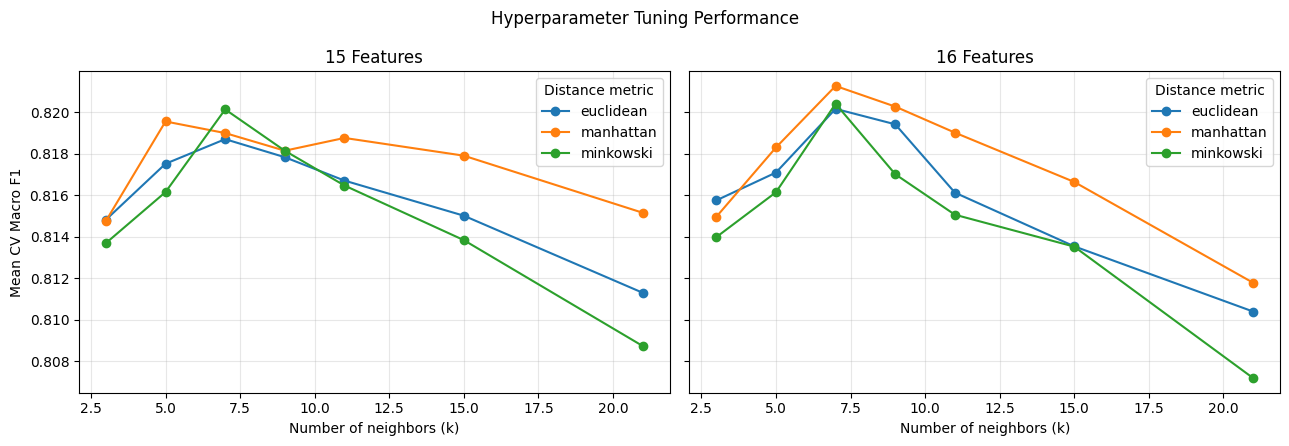

Cross-validation scores for the top 3 configurations


,"16 features, manhattan, k=7","16 features, minkowski, k=7","16 features, manhattan, k=9"
Fold 1,0.82781,0.82296,0.81966
Fold 2,0.81894,0.82355,0.81963
Fold 3,0.81019,0.80852,0.81346
Fold 4,0.82685,0.82742,0.82724
Fold 5,0.82251,0.81955,0.82132


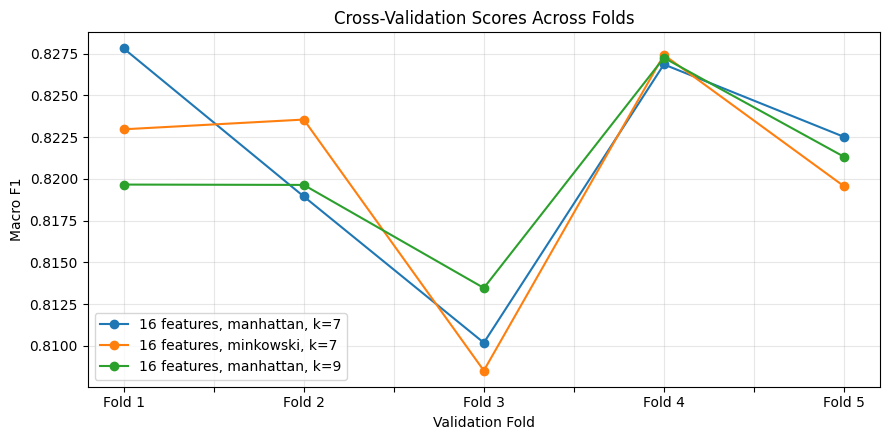

In [27]:
tuning_results = results["hyper"].copy()

best_per_metric = (
    tuning_results.sort_values("cv_macro_f1", ascending=False)
    .drop_duplicates(subset=["n_features", "metric"])
    .sort_values(["n_features", "cv_macro_f1"], ascending=[False, False])
)

print("Best configuration for each feature set and distance metric")
display(
    best_per_metric[
        ["n_features", "metric", "k", "cv_macro_f1", "cv_f1_sd"]
    ].round(5).reset_index(drop=True)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for ax, n_features in zip(axes, [15, 16]):
    subset = tuning_results[tuning_results["n_features"] == n_features]

    performance = subset.pivot(
        index="k",
        columns="metric",
        values="cv_macro_f1"
    ).sort_index()

    performance.plot(ax=ax, marker="o")
    ax.set_title(f"{n_features} Features")
    ax.set_xlabel("Number of neighbors (k)")
    ax.set_ylabel("Mean CV Macro F1")
    ax.grid(alpha=0.3)
    ax.legend(title="Distance metric")

fig.suptitle("Hyperparameter Tuning Performance")
plt.tight_layout()
plt.show()

top_configs = tuning_results.nlargest(3, "cv_macro_f1").copy()
fold_columns = [f"fold{i}_f1" for i in range(1, 6)]

fold_scores = top_configs[fold_columns].T
fold_scores.index = [f"Fold {i}" for i in range(1, 6)]
fold_scores.columns = [
    f"{row.n_features} features, {row.metric}, k={row.k}"
    for row in top_configs.itertuples()
]

print("Cross-validation scores for the top 3 configurations")
display(fold_scores.round(5))

ax = fold_scores.plot(marker="o", figsize=(9, 4.5))
ax.set_title("Cross-Validation Scores Across Folds")
ax.set_xlabel("Validation Fold")
ax.set_ylabel("Macro F1")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Insights

- Hasil *hyperparameter tuning* menunjukkan bahwa konfigurasi **16 fitur, Manhattan distance, dan k=7** memperoleh rata-rata Macro F1 tertinggi pada 5-fold cross-validation, yaitu **0,82126**.
- Perbandingan kedua kandidat fitur menunjukkan bahwa penambahan `room_category` pada kombinasi 16 fitur memberikan peningkatan performa terbaik pada konfigurasi yang diuji.
- Visualisasi menunjukkan bahwa nilai k dan *distance metric* memengaruhi performa KNN. Konfigurasi terbaik berbeda antarrepresentasi fitur sehingga pemilihan parameter perlu mempertimbangkan kombinasi fitur yang digunakan.
- Hasil cross-validation memperlihatkan adanya variasi skor antar-fold. Oleh karena itu, pemilihan model mempertimbangkan performa rata-rata pada seluruh fold, bukan hanya hasil dari satu pembagian data.
- Pengembangan selanjutnya dapat mengeksplorasi metode normalisasi alternatif, pembobotan fitur, dan penanganan ketidakseimbangan kelas untuk meningkatkan kemampuan model mengenali reservasi yang dibatalkan.

---

# Comparison with scikit-learn <a name="8"></a>

---

In [28]:
print(f"Scratch macro F1 = {evaluation['macro_f1']:.6f}")
print(f"scikit-learn macro F1 = {evaluation['sklearn_macro_f1']:.6f}")
print(f"Prediction agreement = {evaluation['sklearn_agreement']:.2%}")
assert evaluation["sklearn_agreement"] == 1.0

Scratch macro F1 = 0.828295
scikit-learn macro F1 = 0.828295
Prediction agreement = 100.00%


#### Insights

Kecocokan prediksi scratch dan scikit-learn pada holdout mencapai **100%** untuk konfigurasi akhir. Hal ini mendukung bahwa implementasi majority voting dan pemilihan tetangga pada percobaan ini sudah konsisten dengan pembanding.

---

# Saving and Loading Models <a name="9"></a>

---

Model final disimpan sebagai `model.pkl` yang berisi KNN hasil fit pada **seluruh training bersih**, daftar fitur, dan state preprocessing. File ini kemudian dimuat kembali dan diperiksa agar hasil prediksi tidak berubah. 

In [29]:
with (CFG.OUTPUT_DIR / "model.pkl").open("rb") as handle:
    loaded_payload = pickle.load(handle)

loaded_preprocessor = restore_preprocessor(loaded_payload["preprocessor_state"])
loaded_test_matrix = loaded_preprocessor.transform(add_features(test_df), loaded_payload["features"])
loaded_predictions = loaded_payload["model"].predict(loaded_test_matrix)
assert np.array_equal(loaded_predictions, results["submission"][TARGET].to_numpy())
print(f"Saved training rows = {len(loaded_payload['model'].X_train_)}")
print(f"Saved numeric columns = {loaded_payload['model'].X_train_.shape[1]}")
print("Save/load predictions = identical")

Saved training rows = 27309
Saved numeric columns = 26
Save/load predictions = identical


---

# Kaggle Submission <a name="10"></a>

---

In [30]:
submission_path = CFG.OUTPUT_DIR / "submission.csv"
submission = pd.read_csv(submission_path, dtype={"id": str})
assert submission.columns.tolist() == ["id", TARGET]
assert submission["id"].equals(test_df["id"])
assert submission["id"].equals(sample_submission["id"])
assert not submission["id"].duplicated().any()
assert submission[TARGET].notna().all()
assert submission[TARGET].isin([0, 1]).all()
assert np.array_equal(submission[TARGET].to_numpy(), loaded_predictions)
print(f"Submission rows = {len(submission)}")
print(f"Submission saved = {submission_path}")
display(submission.head())

Submission rows = 6844
Submission saved = C:\Users\asus\OneDrive\Documents\GitHub\IF3170_G04_TreeIsAllYouNeed\output\knn\submission.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

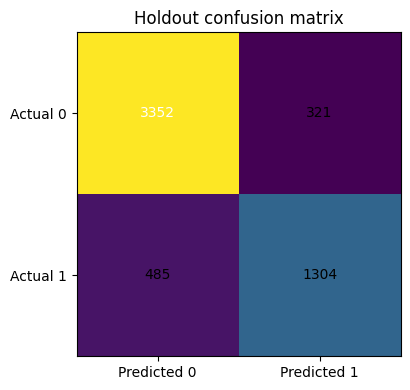

False positives = 321
False negatives = 485


In [31]:
matrix = evaluation["confusion_matrix"]
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(matrix)
ax.set_xticks([0, 1], labels=["Predicted 0", "Predicted 1"])
ax.set_yticks([0, 1], labels=["Actual 0", "Actual 1"])
for row in range(2):
    for column in range(2):
        ax.text(column, row, str(matrix[row, column]), ha="center", va="center", color="white" if matrix[row, column] > matrix.max() / 2 else "black")
ax.set_title("Holdout confusion matrix")
plt.tight_layout()
plt.show()
print(f"False positives = {int(matrix[0, 1])}")
print(f"False negatives = {int(matrix[1, 0])}")

#### Insights

- Berdasarkan *confusion matrix* pada data holdout, model menghasilkan **321 false positive** dan **485 false negative**.
- Jumlah *false negative* yang lebih tinggi menunjukkan bahwa model lebih sering gagal mendeteksi reservasi yang sebenarnya dibatalkan dibandingkan salah memprediksi reservasi yang tidak dibatalkan.
- Hasil ini menunjukkan bahwa model masih memiliki keterbatasan dalam mengenali kelas pembatalan (`1`), meskipun performa keseluruhannya cukup baik.
- Perbaikan selanjutnya dapat difokuskan pada peningkatan kemampuan model mendeteksi pembatalan, dengan tetap mempertimbangkan keseimbangan kesalahan pada kedua kelas.

---

# Bonus: Cost-Sensitive Classification

---

## Penanganan

Sesuai spesifikasi, **False Positive (FP) memiliki biaya dua kali lebih besar daripada False Negative (FN)** karena prediksi pembatalan yang keliru dapat menyebabkan penginapan mengalami *overbooking*. Oleh karena itu, evaluasi tidak hanya mempertimbangkan jumlah kesalahan, tetapi juga biaya yang ditimbulkan.

Dengan biaya FP = 2, FN = 1, dan prediksi benar = 0, total biaya kesalahan dihitung sebagai:

$$
\text{Total Cost} = 2 \times FP + FN
$$

Pada KNN, penanganan dilakukan melalui penyesuaian *decision threshold* berdasarkan proporsi tetangga berlabel `1`. Jika proporsi tersebut adalah $p$, biaya harapan untuk memprediksi kelas `1` sebesar $2(1-p)$, sedangkan biaya harapan untuk memprediksi kelas `0` sebesar $p$. Dengan demikian, kelas `1` dipilih ketika:

$$
\begin{aligned}
2(1-p) &\leq p \\
2-2p &\leq p \\
p &\geq \frac{2}{3}
\end{aligned}
$$

Pada konfigurasi akhir **k=7**, penyesuaian ini mengubah syarat prediksi dibatalkan dari minimal **4 menjadi 5 tetangga** berlabel `1`.

Perubahan diterapkan sebagai *post-processing* prediksi pada data holdout, menggunakan konfigurasi dan preprocessing yang sama dengan model utama. Implementasi KNN dan submission Kaggle tidak diubah.

In [33]:
from sklearn.metrics import confusion_matrix, f1_score
from algoritma.knn.knn import KNN

bonus_root = next(
    (path for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (path / "src/kaggle/dataset/train.csv").exists()),
    None
)
if bonus_root is None:
    raise FileNotFoundError("Project dataset not found")

sys.path.insert(0, str(bonus_root / "src"))

bonus_tuning = pd.read_csv(bonus_root / "output/knn/tuning.csv")
bonus_best = (
    bonus_tuning[bonus_tuning["stage"] == "joint_tuning_cv5"]
    .sort_values(["cv_macro_f1", "cv_f1_sd"], ascending=[False, True])
    .iloc[0]
)

bonus_train = clean_training_data(
    pd.read_csv(bonus_root / "src/kaggle/dataset/train.csv", dtype={"id": str})
)
bonus_y = bonus_train[TARGET].to_numpy(np.int8)

bonus_dev, bonus_holdout = train_test_split(
    np.arange(len(bonus_train)),
    test_size=0.2,
    random_state=42,
    stratify=bonus_y
)

bonus_data = add_features(bonus_train)
bonus_preprocessor = BookingPreprocessor().fit(bonus_data.iloc[bonus_dev])
bonus_features = bonus_best["features"].split(";")

bonus_X_dev = bonus_preprocessor.transform(
    bonus_data.iloc[bonus_dev], bonus_features
)
bonus_X_holdout = bonus_preprocessor.transform(
    bonus_data.iloc[bonus_holdout], bonus_features
)

bonus_model = KNN(
    n_neighbors=int(bonus_best["k"]),
    metric=bonus_best["metric"],
    p=int(bonus_best["p"])
).fit(bonus_X_dev, bonus_y[bonus_dev])

cost_fp, cost_fn = 2, 1
threshold = cost_fp / (cost_fp + cost_fn)

positive_class = np.flatnonzero(bonus_model.classes_ == 1)[0]
probability = bonus_model.predict_proba(bonus_X_holdout)[:, positive_class]

predictions = {
    "KNN Standard": bonus_model.predict(bonus_X_holdout),
    "Cost-Sensitive KNN": (probability >= threshold).astype(np.int8)
}

comparison = []
for approach, predicted in predictions.items():
    tn, fp, fn, tp = confusion_matrix(
        bonus_y[bonus_holdout], predicted, labels=[0, 1]
    ).ravel()

    comparison.append({
        "Approach": approach,
        "FP": int(fp),
        "FN": int(fn),
        "Total Cost": int(cost_fp * fp + cost_fn * fn),
        "Macro F1": f1_score(
            bonus_y[bonus_holdout], predicted, average="macro"
        )
    })

comparison_df = pd.DataFrame(comparison).set_index("Approach")
display(comparison_df.round(5))

standard_cost = comparison_df.loc["KNN Standard", "Total Cost"]
sensitive_cost = comparison_df.loc["Cost-Sensitive KNN", "Total Cost"]

print(f"Decision threshold = {threshold:.4f}")
print(f"Cost reduction = {(standard_cost - sensitive_cost) / standard_cost * 100:.2f}%")


,FP,FN,Total Cost,Macro F1
Approach,,,,
KNN Standard,321,485,1127,0.82829
Cost-Sensitive KNN,177,673,1027,0.80791


Decision threshold = 0.6667
Cost reduction = 8.87%


## Analisis Hasil

Penerapan *cost-sensitive classification* mengurangi jumlah False Positive dari **321 menjadi 177**, tetapi meningkatkan False Negative dari **485 menjadi 673**. Hal ini terjadi karena peningkatan *decision threshold* membuat model lebih berhati-hati dalam memprediksi reservasi sebagai dibatalkan.

Dengan asumsi biaya FP = 2 dan FN = 1, total biaya kesalahan berkurang dari **1.127 menjadi 1.027**, atau turun sebesar **8,87%**. Penurunan 144 FP menghemat 288 unit biaya, sedangkan tambahan 188 FN meningkatkan biaya sebesar 188 unit. Dengan demikian, diperoleh penghematan bersih sebesar **100 unit biaya**.

Meskipun Macro F1 menurun dari **0,82830 menjadi 0,80791**, pendekatan cost-sensitive lebih sesuai dengan asumsi biaya yang ditetapkan karena berhasil mengurangi total biaya kesalahan. Hasil ini menunjukkan bahwa penanganan klasifikasi dapat disesuaikan dengan konsekuensi masing-masing kesalahan, tanpa perlu mengubah proses pelatihan atau implementasi dasar KNN.